# Chapter 2. Background Research

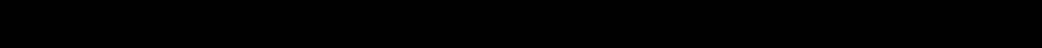

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Find the project directory
if Path.cwd().name == "notebooks":
    project_dir = Path.cwd().parent
else:
    project_dir = Path.cwd()

sys.path.append(str(project_dir))


from src.denoisers import (
    anisotropic_denoise,
    total_variation_denoise,
    bilateral_denoise,
    non_local_means_denoise
)

from src.noise import add_gaussian_noise
from src.utils import (
    load_grayscale_image,
    show_images
)

# Set the data and output folders
test_dir = project_dir / "data" / "background_research_examples"
plot_dir = project_dir / "results" / "Chapter2_DenoisingMethods"
os.makedirs(plot_dir, exist_ok=True)


## 2.1 Image Noise and Denoising

The following example shows the effect of increasing Gaussian noise. The same clean image is used at three noise levels, so the change in image quality can be compared directly.


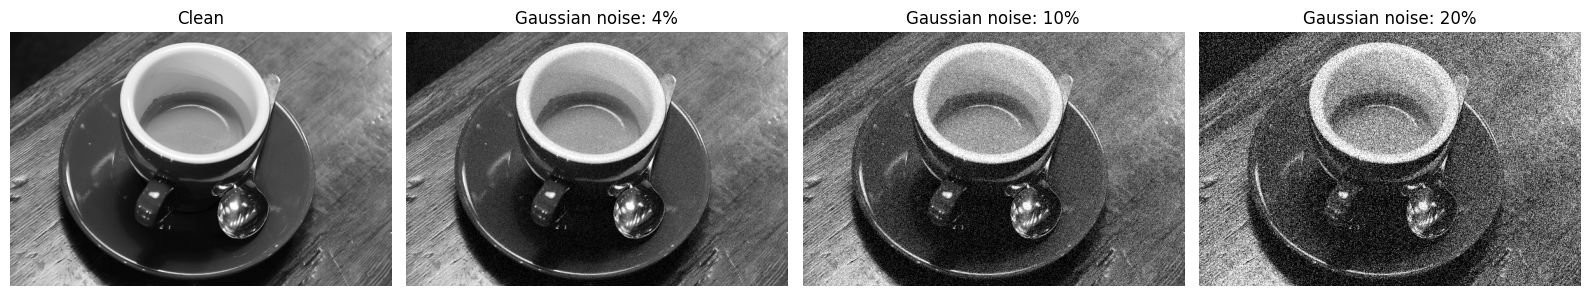

In [2]:
# Load the clean coffee image
clean_image = load_grayscale_image(
    os.path.join(test_dir, "coffee.png")
)

# Add Gaussian noise
noise_levels = [4, 10, 20]
noisy_images = []

for noise_percent in noise_levels:
    noisy_image = add_gaussian_noise(
        clean_image,
        sigma=noise_percent / 100.0,
        seed=42
    )
    noisy_images.append(noisy_image)

# Show and save the comparison
images = [clean_image] + noisy_images
titles = ["Clean"] + [
    f"Gaussian noise: {noise_percent}%"
    for noise_percent in noise_levels
]

show_images(
    images,
    titles,
    save_path=os.path.join(
        plot_dir,
        "gaussian_noise_levels.png"
    )
)


## 2.2 Edge-Preserving Denoising Methods

The following examples illustrate the main behaviour of the four denoising methods. Each example focuses on one key parameter that is useful for understanding the method.


### 2.2.1 Anisotropic Diffusion

Anisotropic diffusion smooths the image according to local intensity changes. The example below shows the conduction map and the resulting denoised image. Low conduction values limit smoothing near strong boundaries.


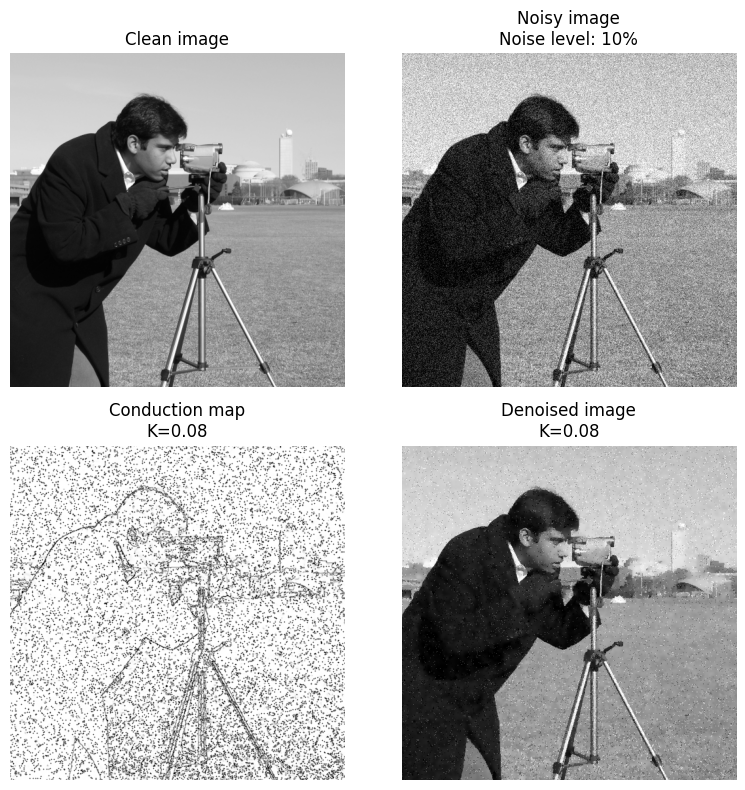

In [3]:
# Load the clean camera image
clean_image = load_grayscale_image(
    os.path.join(test_dir, "camera.png")
)

# Add Gaussian noise at 10%
noise_percent = 10
sigma = noise_percent / 100.0

noisy_image = add_gaussian_noise(clean_image, sigma=sigma,seed=42)

# Apply anisotropic diffusion
n_iter = 30
gamma = 0.2
kappa = 0.08

denoised_image, conduction_map = anisotropic_denoise(
    noisy_image,
    n_iter=n_iter,
    kappa=kappa,
    gamma=gamma,
    conduction="exponential"
)

# Create a 2 × 2 figure
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

# Display the clean image
axes[0, 0].imshow(clean_image,cmap="gray",vmin=0,vmax=1)
axes[0, 0].set_title("Clean image")

# Display the noisy image
axes[0, 1].imshow(noisy_image,cmap="gray",vmin=0,vmax=1)
axes[0, 1].set_title(f"Noisy image\nNoise level: {noise_percent}%")

# Display the conduction map
axes[1, 0].imshow(conduction_map,cmap="gray",vmin=0,vmax=1)
axes[1, 0].set_title(f"Conduction map\nK={kappa:.2f}")

# Display the denoised image
axes[1, 1].imshow(denoised_image,cmap="gray",vmin=0,vmax=1)
axes[1, 1].set_title(f"Denoised image\nK={kappa:.2f}")

for axis in axes.flat:
    axis.axis("off")

plt.tight_layout()

# Save the figure
plt.savefig(
    os.path.join(plot_dir,"anisotropic_diffusion_conduction_map.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 2.2.2 Total Variation Denoising

Total variation denoising favours piecewise smooth regions while keeping sharp boundaries. The example below uses an intensity profile to show the staircasing effect that can appear under stronger regularisation.


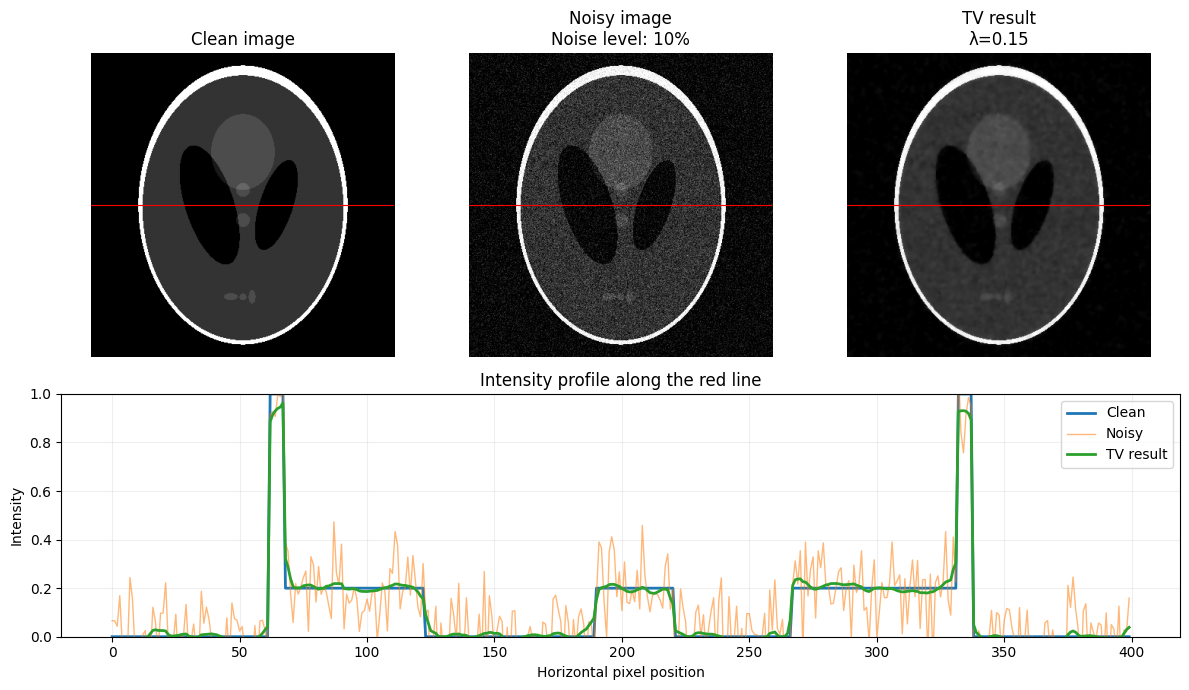

In [4]:
# Load the clean camera image
clean_image = load_grayscale_image(
    os.path.join(test_dir, "phantom.png")
)

# Add Gaussian noise at 10%
noise_percent = 10
sigma = noise_percent / 100.0

noisy_image = add_gaussian_noise(clean_image,sigma=sigma,seed=42)

# Apply TV denoising
lambda_value = 0.15
tv_result = total_variation_denoise(noisy_image,weight=lambda_value)

# Select a horizontal line through the main objects
profile_row = clean_image.shape[0] // 2
x_positions = np.arange(clean_image.shape[1])

# Create the figure
fig = plt.figure(figsize=(12, 7))
grid = fig.add_gridspec(2,3,height_ratios=[1, 0.8])

image_axes = [
    fig.add_subplot(grid[0, 0]),
    fig.add_subplot(grid[0, 1]),
    fig.add_subplot(grid[0, 2])
]

# Display the clean image
image_axes[0].imshow(clean_image, cmap="gray", vmin=0, vmax=1)
image_axes[0].set_title("Clean image")

# Display the noisy image
image_axes[1].imshow(noisy_image, cmap="gray",vmin=0,vmax=1)
image_axes[1].set_title(f"Noisy image\nNoise level: {noise_percent}%")

# Display the TV result
image_axes[2].imshow(tv_result,cmap="gray",vmin=0,vmax=1)
image_axes[2].set_title(f"TV result\nλ={lambda_value:.2f}")

# Mark the profile position
for axis in image_axes:
    axis.axhline(profile_row,color="red",linewidth=0.8)
    axis.axis("off")

# Plot the intensity profiles
profile_axis = fig.add_subplot(grid[1, :])

profile_axis.plot(x_positions,clean_image[profile_row],label="Clean",linewidth=2)
profile_axis.plot(x_positions,noisy_image[profile_row],label="Noisy",linewidth=1,alpha=0.55)

profile_axis.plot(x_positions,tv_result[profile_row],label="TV result",linewidth=2)

profile_axis.set_xlabel("Horizontal pixel position")
profile_axis.set_ylabel("Intensity")
profile_axis.set_ylim(0, 1)
profile_axis.set_title("Intensity profile along the red line")
profile_axis.legend()
profile_axis.grid(alpha=0.2)

plt.tight_layout()

# Save the figure
plt.savefig(
    os.path.join(plot_dir,"total_variation_camera_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.2.3 Bilateral Filtering

Bilateral filtering uses both spatial distance and intensity difference when averaging nearby pixels. The parameter grid below shows how the spatial and range parameters affect the amount of smoothing and edge preservation.


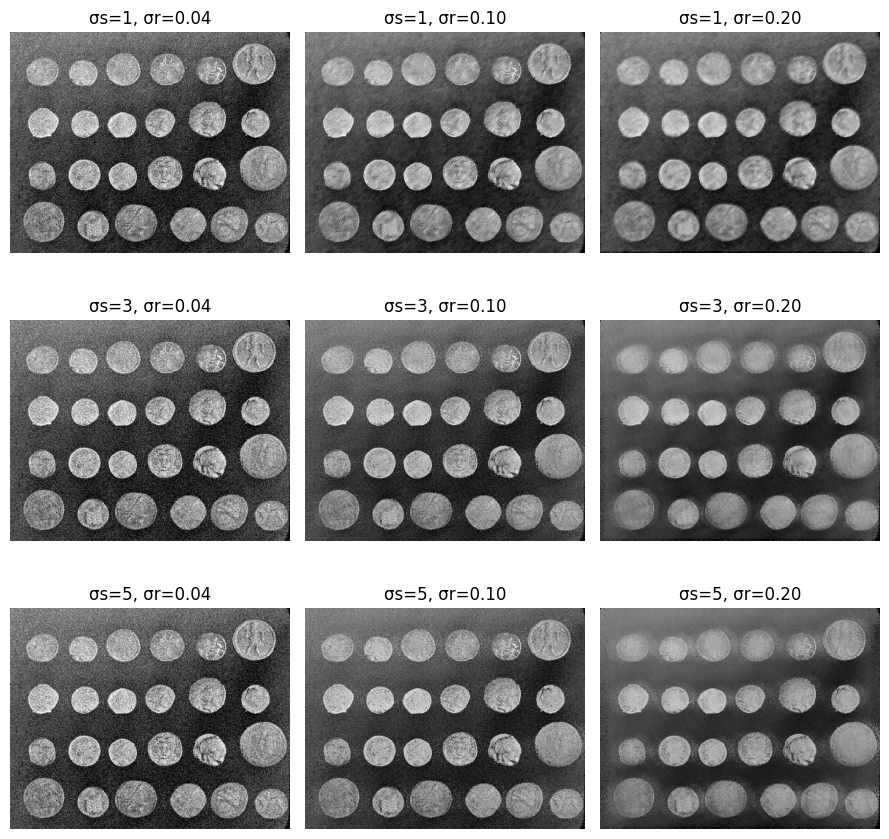

In [5]:
# Load the clean cat image
clean_image = load_grayscale_image(
    os.path.join(test_dir, "coins.png")
)

# Add Gaussian noise at 10%
noise_percent = 10
sigma = noise_percent / 100.0
noisy_image = add_gaussian_noise(clean_image,sigma=sigma,seed=42)

# Test different parameter combinations
sigma_spatial_values = [1, 3, 5]
sigma_range_values = [0.04, 0.10, 0.20]

# Create a 3 × 3 parameter grid
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for row, sigma_spatial in enumerate(sigma_spatial_values):
    for col, sigma_range in enumerate(sigma_range_values):
        denoised_image = bilateral_denoise(noisy_image,sigma_color=sigma_range,sigma_spatial=sigma_spatial)

        axes[row, col].imshow(denoised_image,cmap="gray",vmin=0,vmax=1)
        axes[row, col].set_title(f"σs={sigma_spatial}, σr={sigma_range:.2f}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig(
    os.path.join(plot_dir,"bilateral_filter_parameter_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 2.2.4 Non-Local Means

Non-local means compares small image patches and averages pixels with similar neighbourhoods. The example below uses one image with irregular detail and one with repeated structure. The same value of $h$ is used for both images.


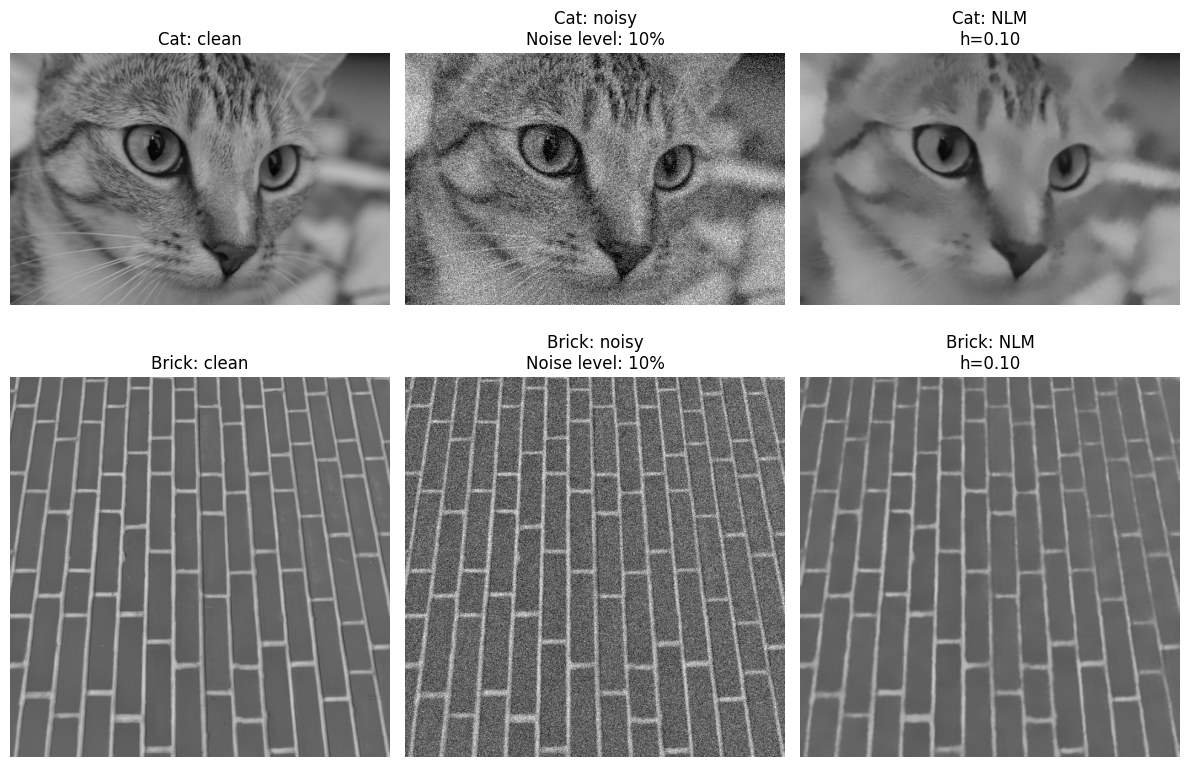

In [6]:
# Load images with different structures
cat_image = load_grayscale_image(
    os.path.join(test_dir, "cat.png")
)

brick_image = load_grayscale_image(
    os.path.join(test_dir, "brick.png")
)

clean_images = [cat_image, brick_image]
image_names = ["Cat", "Brick"]

# Keep all NLM settings fixed
noise_percent = 10
sigma = noise_percent / 100.0
h = 0.10
patch_size = 7
patch_distance = 10

# Compare the clean, noisy, and denoised images
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for row, clean_image in enumerate(clean_images):
    # Add Gaussian noise
    noisy_image = add_gaussian_noise(clean_image,sigma=sigma,seed=42)

    # Apply non-local means denoising
    denoised_image = non_local_means_denoise(
        noisy_image,
        h=h,
        patch_size=patch_size,
        patch_distance=patch_distance
    )

    # Display the clean image
    axes[row, 0].imshow(clean_image,cmap="gray",vmin=0,vmax=1)
    axes[row, 0].set_title(f"{image_names[row]}: clean")

    # Display the noisy image
    axes[row, 1].imshow(noisy_image,cmap="gray",vmin=0,vmax=1)
    axes[row, 1].set_title(
        f"{image_names[row]}: noisy\n"
        f"Noise level: {noise_percent}%"
    )

    # Display the denoised image
    axes[row, 2].imshow(denoised_image,cmap="gray", vmin=0,vmax=1)
    axes[row, 2].set_title(f"{image_names[row]}: NLM\nh={h:.2f}")

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(plot_dir,"non_local_means_structure_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
